<a href="https://colab.research.google.com/github/Snehamn24/UAV_swarm_path_optimization/blob/main/UAV_swarm_path.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1.Project Introduction and Probelm statement


# UAV Swarm Path Planning Optimization Using Genetic Algorithm

## 1. Introduction

Unmanned Aerial Vehicles (UAVs), commonly known as drones, are increasingly used in applications such as disaster management, surveillance, agriculture, search and rescue, and logistics.

When multiple UAVs operate together as a swarm, they must coordinate their movements and navigate through an environment while avoiding obstacles and maintaining safe distances from one another.

Finding optimal paths for multiple UAVs is a challenging optimization problem because the system must consider several factors, including path length, obstacle avoidance, collision prevention, and overall swarm efficiency.

This project proposes a Soft Computing-based optimization approach for UAV swarm path planning using a Genetic Algorithm (GA).

## 2. Problem Statement

To develop a simulation-based UAV swarm path planning system that determines efficient and collision-aware routes for multiple UAVs operating in an environment containing static and dynamic obstacles.

The system aims to minimize total travel distance while considering obstacle avoidance, inter-UAV separation, and route smoothness.

## 3. Objectives

1. Develop a simulated environment containing multiple UAVs, destinations, and obstacles.
2. Implement a Genetic Algorithm to optimize the paths of multiple UAVs.
3. Design a fitness function considering distance, obstacle avoidance, collision prevention, and path smoothness.
4. Implement an Adaptive Genetic Algorithm to improve optimization behaviour.
5. Extend the environment to include moving obstacles.
6. Compare Genetic Algorithm performance with Particle Swarm Optimization and Simulated Annealing.
7. Evaluate the algorithms using performance metrics and graphical visualizations.

## 4. Role of Soft Computing

Soft Computing provides approximate and intelligent optimization techniques for solving complex problems.

This project primarily uses Genetic Algorithms, which are inspired by natural selection and evolution. Candidate routes are treated as individuals in a population. Selection, crossover, and mutation operations are used to improve the quality of routes over successive generations.

Adaptive Genetic Algorithm, Particle Swarm Optimization, and Simulated Annealing are also considered to investigate and compare different optimization strategies.

# 2.Importing Required Libraries

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import random # generating random solutions and mutations
import math
import copy # creating independent copies of candidate solutions

print("Libraries imported successfully!")

Libraries imported successfully!


# 3.Defining the UAV Environment

Initilly the simulation will use a 2D environment

Think of it as a map with:
- X-axis: Horizontal position.
- Y-axis: Vertical position.
- Rectangular obstacles: Restricted areas.
- UAVs: Drones that must navigate around obstacles.

In [4]:
# Define the simulation environment dimensions

MAP_WIDTH = 100
MAP_HEIGHT = 100

# Define rectangular obstacles
# Format: (x, y, width, height)

obstacles = [
    (20, 20, 15, 25),
    (50, 10, 20, 15),
    (65, 55, 15, 25),
    (25, 65, 20, 15)
]

print("Environment created successfully!")
print("Map dimensions:", MAP_WIDTH, "x", MAP_HEIGHT)
print("Number of obstacles:", len(obstacles))

Environment created successfully!
Map dimensions: 100 x 100
Number of obstacles: 4


# 4.Defining UAV start and Goal positionns

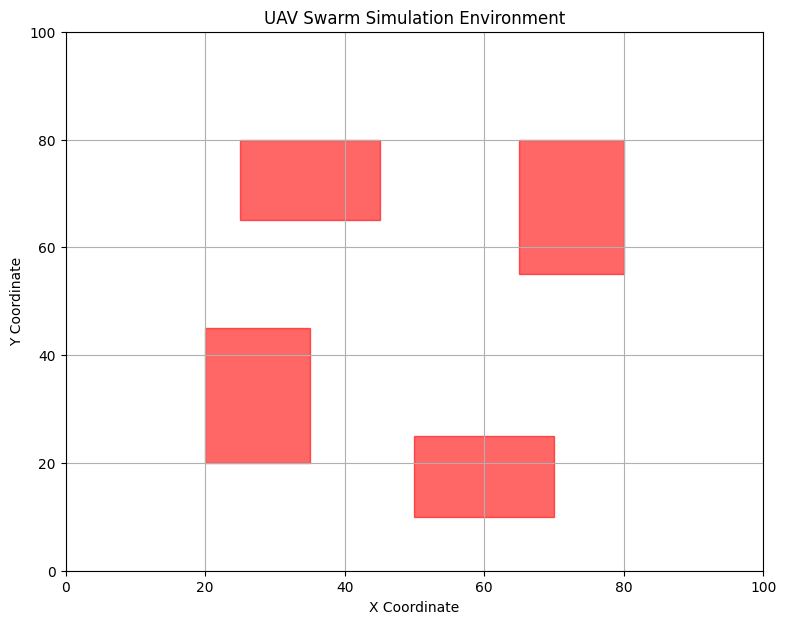

In [5]:
plt.figure(figsize=(9, 7))

# Draw obstacles
for x, y, width, height in obstacles:
    rectangle = plt.Rectangle(
        (x, y),
        width,
        height,
        color="red",
        alpha=0.6
    )

    plt.gca().add_patch(rectangle)

# Configure map
plt.xlim(0, MAP_WIDTH)
plt.ylim(0, MAP_HEIGHT)

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title("UAV Swarm Simulation Environment")

plt.grid(True)
plt.show()

# Metrics

Total path length: How far all UAVs travel
Obstacle collisions: Whether routes intersect obstacles
UAV separation violations: Whether drones come too close
Convergence: How quickly the algorithm improves
Execution time: How long optimization takes
Fitness value: Overall quality according to our objective function


# 5.Define UAVs, starting positions and destinations




In [6]:
# ============================================
# CELL 5: UAV INITIALIZATION
# ============================================

# Number of UAVs in the swarm
NUM_UAVS = 3

# Starting positions of UAVs
start_positions = np.array([
    [5, 5],
    [5, 90],
    [90, 5]
], dtype=float)

# Destination positions of UAVs
goal_positions = np.array([
    [90, 90],
    [90, 90],
    [90, 90]
], dtype=float)

# Display UAV information
print("UAV Swarm Initialization")
print("-------------------------")

for i in range(NUM_UAVS):
    print(f"\nUAV {i + 1}")
    print("Start Position:", start_positions[i])
    print("Goal Position :", goal_positions[i])

print("\nTotal UAVs:", NUM_UAVS)

UAV Swarm Initialization
-------------------------

UAV 1
Start Position: [5. 5.]
Goal Position : [90. 90.]

UAV 2
Start Position: [ 5. 90.]
Goal Position : [90. 90.]

UAV 3
Start Position: [90.  5.]
Goal Position : [90. 90.]

Total UAVs: 3


# 6.Generate initial routes

In [7]:
# ============================================
# CELL 6: INITIAL ROUTE GENERATION
# ============================================

# Number of intermediate waypoints per UAV
NUM_WAYPOINTS = 5

# Generate one candidate route for a UAV
def generate_random_route(start, goal, num_waypoints):

    route = []

    for i in range(1, num_waypoints + 1):

        # Generate random intermediate coordinates
        x = random.uniform(0, MAP_WIDTH)
        y = random.uniform(0, MAP_HEIGHT)

        route.append([x, y])

    # Add start and destination
    complete_route = [start.tolist()] + route + [goal.tolist()]

    return np.array(complete_route, dtype=float)


# Generate initial routes for all UAVs
initial_routes = []

for i in range(NUM_UAVS):

    route = generate_random_route(
        start_positions[i],
        goal_positions[i],
        NUM_WAYPOINTS
    )

    initial_routes.append(route)


# Display route information
for i, route in enumerate(initial_routes):

    print(f"\nUAV {i + 1} Initial Route")

    for point in route:
        print(point)


UAV 1 Initial Route
[5. 5.]
[26.28327282 51.19567572]
[94.37045626 39.95580424]
[72.4134396  87.72836468]
[24.08767834 97.57102479]
[34.09065951 22.4310473 ]
[90. 90.]

UAV 2 Initial Route
[ 5. 90.]
[ 8.69737395 63.92263454]
[99.0950968  83.16539823]
[83.03473952 18.67541411]
[23.78313809 65.94683336]
[71.81698114 22.0872855 ]
[90. 90.]

UAV 3 Initial Route
[90.  5.]
[24.42618215 26.53982016]
[ 1.77946858 25.63674776]
[97.83802389 54.15570631]
[92.72537011 86.52361687]
[97.01074032 89.56834267]
[90. 90.]


The generate_random_route() function creates a route containing:
- One starting position.
- Five randomly generated intermediate waypoints.
- One destination.

# 7. Visualize initial UAV routes

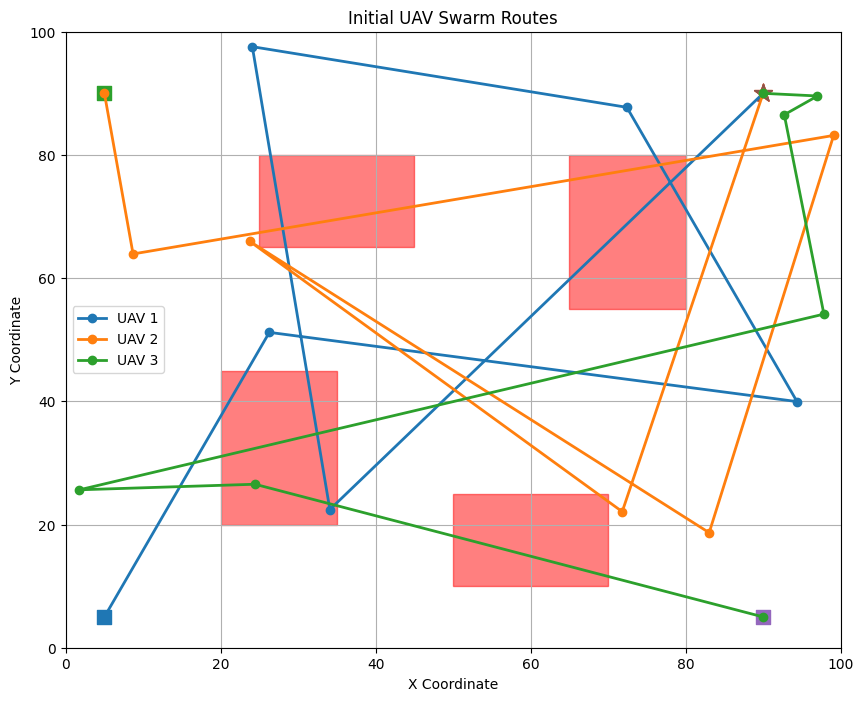

In [8]:
# ============================================
# CELL 7: INITIAL ROUTE VISUALIZATION
# ============================================

plt.figure(figsize=(10, 8))

# Draw obstacles
for x, y, width, height in obstacles:

    rectangle = plt.Rectangle(
        (x, y),
        width,
        height,
        color="red",
        alpha=0.5
    )

    plt.gca().add_patch(rectangle)


# Plot each UAV route
for i, route in enumerate(initial_routes):

    plt.plot(
        route[:, 0],
        route[:, 1],
        marker="o",
        linewidth=2,
        label=f"UAV {i + 1}"
    )

    # Mark starting position
    plt.scatter(
        route[0, 0],
        route[0, 1],
        marker="s",
        s=100
    )

    # Mark destination
    plt.scatter(
        route[-1, 0],
        route[-1, 1],
        marker="*",
        s=180
    )


plt.xlim(0, MAP_WIDTH)
plt.ylim(0, MAP_HEIGHT)

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.title("Initial UAV Swarm Routes")

plt.legend()
plt.grid(True)

plt.show()

- Three different UAV routes.



- Squares representing starting positions.



- Stars representing destinations.



- Red rectangles representing obstacles.



- Routes may pass through obstacles or come close to other UAV routes.

# 6.Fitness Function Design

# What is Fitness Functions?
- A Genetic Algorithm needs a method to determine whether one solution is better than another.
This is done using the fitness function

- F = w_1L+w_2O+w_3C+w_4S

where,
- L: Total path Length
- O: Obstacle collision penalty
- C: Inter-UAV proximity penalty
- S: Path smoothness penalty
- w1,w2,w3,w4: Weight assigned to each factor

A lower fitness value represents a better route under our objective function

# 8.Calculate path length
uses euclidian distance

In [9]:
# ============================================
# CELL 8: PATH LENGTH CALCULATION
# ============================================

def calculate_path_length(route):

    total_distance = 0

    for i in range(len(route) - 1):

        point1 = route[i]
        point2 = route[i + 1]

        distance = np.linalg.norm(point2 - point1)

        total_distance += distance

    return total_distance


# Calculate distance for each initial route
for i, route in enumerate(initial_routes):

    distance = calculate_path_length(route)

    print(f"UAV {i + 1} Path Length: {distance:.2f}")

UAV 1 Path Length: 385.27
UAV 2 Path Length: 396.37
UAV 3 Path Length: 236.94


# 9.Detect Obstacle collisions

In [10]:
# ============================================
# CELL 9: OBSTACLE COLLISION DETECTION
# ============================================

def point_inside_obstacle(point, obstacle):

    x, y = point

    ox, oy, width, height = obstacle

    return (
        ox <= x <= ox + width and
        oy <= y <= oy + height
    )


def calculate_obstacle_penalty(route):

    collision_count = 0

    # Examine every route segment
    for i in range(len(route) - 1):

        start = route[i]
        end = route[i + 1]

        # Generate intermediate sample points
        sample_points = np.linspace(
            start,
            end,
            30
        )

        # Check whether sample points intersect obstacles
        for point in sample_points:

            for obstacle in obstacles:

                if point_inside_obstacle(point, obstacle):

                    collision_count += 1

    return collision_count


# Test obstacle detection
for i, route in enumerate(initial_routes):

    penalty = calculate_obstacle_penalty(route)

    print(f"UAV {i + 1} Obstacle Penalty: {penalty}")

UAV 1 Obstacle Penalty: 34
UAV 2 Obstacle Penalty: 10
UAV 3 Obstacle Penalty: 25


The function checks each route segment using 30 sample points.

If a sample point lies inside an obstacle, the collision penalty increases.

This is a simplified sampling-based detector. It is useful for our initial experiment, but it can miss a narrow intersection between sample points. We can improve it later using exact line-segment/rectangle intersection detection.

# 10.Calculate route smoothness

In [11]:
# ============================================
# CELL 10: ROUTE SMOOTHNESS
# ============================================

def calculate_smoothness(route):

    total_turning_angle = 0

    for i in range(1, len(route) - 1):

        vector1 = route[i] - route[i - 1]

        vector2 = route[i + 1] - route[i]

        norm1 = np.linalg.norm(vector1)
        norm2 = np.linalg.norm(vector2)

        if norm1 == 0 or norm2 == 0:
            continue

        cosine_angle = np.dot(vector1, vector2) / (norm1 * norm2)

        cosine_angle = np.clip(
            cosine_angle,
            -1,
            1
        )

        angle = np.arccos(cosine_angle)

        total_turning_angle += angle

    return total_turning_angle


# Calculate smoothness
for i, route in enumerate(initial_routes):

    smoothness = calculate_smoothness(route)

    print(f"UAV {i + 1} Smoothness Penalty: {smoothness:.4f}")

UAV 1 Smoothness Penalty: 8.6290
UAV 2 Smoothness Penalty: 10.7886
UAV 3 Smoothness Penalty: 8.2610


# 11. Combine fitness Componenets

In [12]:
# ============================================
# CELL 11: INITIAL FITNESS FUNCTION
# ============================================

# Fitness weights
W_DISTANCE = 1.0
W_OBSTACLE = 100.0
W_SMOOTHNESS = 5.0


def calculate_route_fitness(route):

    distance = calculate_path_length(route)

    obstacle_penalty = calculate_obstacle_penalty(route)

    smoothness = calculate_smoothness(route)

    fitness = (
        W_DISTANCE * distance +
        W_OBSTACLE * obstacle_penalty +
        W_SMOOTHNESS * smoothness
    )

    return fitness


# Evaluate initial routes
for i, route in enumerate(initial_routes):

    fitness = calculate_route_fitness(route)

    print(f"UAV {i + 1} Fitness: {fitness:.2f}")

UAV 1 Fitness: 3828.41
UAV 2 Fitness: 1450.31
UAV 3 Fitness: 2778.24


# Stage 3

# 12.Inter-UAV separation penalty

In [13]:
# ============================================
# CELL 12: INTER-UAV SEPARATION PENALTY
# ============================================

MIN_SEPARATION = 10.0

def calculate_swarm_separation_penalty(routes):

    total_penalty = 0

    # Compare every pair of UAVs
    for i in range(len(routes)):

        for j in range(i + 1, len(routes)):

            route1 = routes[i]
            route2 = routes[j]

            # Compare positions at corresponding normalized
            # route progress values
            for t in np.linspace(0, 1, 30):

                index1 = int(t * (len(route1) - 1))
                index2 = int(t * (len(route2) - 1))

                position1 = route1[index1]
                position2 = route2[index2]

                distance = np.linalg.norm(
                    position1 - position2
                )

                if distance < MIN_SEPARATION:

                    total_penalty += (
                        MIN_SEPARATION - distance
                    ) ** 2

    return total_penalty


# Test separation penalty
separation_penalty = calculate_swarm_separation_penalty(
    initial_routes
)

print("Swarm Separation Penalty:", round(separation_penalty, 2))

Swarm Separation Penalty: 300.0


- We compare every pair of UAVs.



- We sample corresponding positions along their routes.



- If the distance is below 10 coordinate units, a penalty is added.



- A larger violation produces a larger penalty

# Stage 4 - Complete swarm fitness function

# 13.Evaluate the entire swarm

- Total path length.



- Obstacle collision penalty.



- Inter-UAV separation penalty.



- Route smoothness.

-
F=w_1L+w_2O+w_3C+w_4S


In [14]:
# ============================================
# CELL 13: COMPLETE SWARM FITNESS FUNCTION
# ============================================

W_DISTANCE = 1.0
W_OBSTACLE = 1000.0
W_SEPARATION = 50.0
W_SMOOTHNESS = 5.0


def calculate_swarm_fitness(routes):

    total_distance = 0
    total_obstacle_penalty = 0
    total_smoothness = 0

    # Evaluate individual UAV routes
    for route in routes:

        total_distance += calculate_path_length(route)

        total_obstacle_penalty += (
            calculate_obstacle_penalty(route)
        )

        total_smoothness += calculate_smoothness(route)

    # Evaluate swarm-level separation
    separation_penalty = (
        calculate_swarm_separation_penalty(routes)
    )

    # Calculate total fitness
    fitness = (
        W_DISTANCE * total_distance
        + W_OBSTACLE * total_obstacle_penalty
        + W_SEPARATION * separation_penalty
        + W_SMOOTHNESS * total_smoothness
    )

    return fitness


# Test complete fitness function
initial_fitness = calculate_swarm_fitness(initial_routes)

print("Initial Swarm Fitness:", round(initial_fitness, 2))

Initial Swarm Fitness: 85156.97


Previously, we evaluated individual routes. Now the fitness function evaluates all three UAV routes as one solution.

This is important because changing one UAV's route can affect the separation between drones.

A candidate solution now contains three complete routes.

# stage 5 - Genetic algorithm implementation

- Understanding the chromosome
In a Genetic Algorithm, a candidate solution is called a chromosome.

In our project:
- One chromosome represents the complete swarm.
- Each chromosome contains three UAV routes.
- Each UAV route contains five intermediate waypoints.
- Each waypoint has an X and Y coordinate.

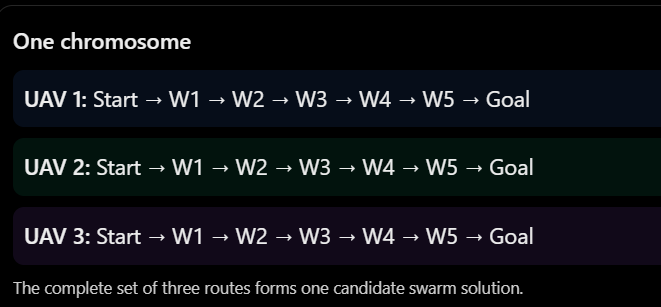

# 14. generate the initial population

A population is a collection of candidate solutions.

We'll generate 50 chromosomes initially.

In [15]:
# ============================================
# CELL 14: INITIAL POPULATION GENERATION
# ============================================

POPULATION_SIZE = 50

def generate_chromosome():

    chromosome = []

    for i in range(NUM_UAVS):

        route = generate_random_route(
            start_positions[i],
            goal_positions[i],
            NUM_WAYPOINTS
        )

        chromosome.append(route)

    return chromosome


def generate_population(population_size):

    population = []

    for _ in range(population_size):

        chromosome = generate_chromosome()

        population.append(chromosome)

    return population


# Generate initial population
population = generate_population(POPULATION_SIZE)

print("Population Generated Successfully!")
print("Population Size:", len(population))
print("UAVs per Chromosome:", NUM_UAVS)
print("Waypoints per UAV:", NUM_WAYPOINTS)

Population Generated Successfully!
Population Size: 50
UAVs per Chromosome: 3
Waypoints per UAV: 5


Every chromosome has a different combination of random routes.

The algorithm evaluates these solutions and selects better chromosomes for reproduction.

# 15.Tournament Selection

What is selection?
- Selection chooses good candidate solutions to become parents

We'll use tournament selection:
1. Randomly choose a few chromosomes.
2. Evaluate their fitness.
3. Select the chromosome with the lowest fitness.
4. Repeat whenever a parent is required.



In [16]:
# ============================================
# CELL 15: TOURNAMENT SELECTION
# ============================================

TOURNAMENT_SIZE = 3


def tournament_selection(population):

    tournament = random.sample(
        population,
        TOURNAMENT_SIZE
    )

    best_chromosome = min(
        tournament,
        key=calculate_swarm_fitness
    )

    return copy.deepcopy(best_chromosome)


# Test tournament selection
selected_parent = tournament_selection(population)

print("Parent Selected Successfully!")

print(
    "Selected Parent Fitness:",
    round(calculate_swarm_fitness(selected_parent), 2)
)

Parent Selected Successfully!
Selected Parent Fitness: 99015.77


We use random.sample() to select three different chromosomes.

The chromosome with the lowest fitness wins the tournament.

This encourages better solutions to reproduce while still allowing diversity in the population.

# 7.Crossover operation
What is crossover?
- Crossover combines 2 parent solutions to generate a new child solution

For example:
- Parent 1 contributes some waypoints.
- Parent 2 contributes the remaining waypoints.
- The child receives a combination of both.

In [17]:
# ============================================
# CELL 16: UNIFORM CROSSOVER
# ============================================

CROSSOVER_RATE = 0.85



def crossover(parent1, parent2):

    child1 = []
    child2 = []

    for uav_index in range(NUM_UAVS):

        route1 = parent1[uav_index]
        route2 = parent2[uav_index]

        child_route1 = route1.copy()
        child_route2 = route2.copy()

        # Exchange intermediate waypoints
        for waypoint_index in range(1, NUM_WAYPOINTS + 1):

            if random.random() < 0.5:

                child_route1[waypoint_index] = (
                    route2[waypoint_index].copy()
                )

                child_route2[waypoint_index] = (
                    route1[waypoint_index].copy()
                )

        # Preserve fixed start and goal positions
        child_route1[0] = start_positions[uav_index].copy()
        child_route1[-1] = goal_positions[uav_index].copy()

        child_route2[0] = start_positions[uav_index].copy()
        child_route2[-1] = goal_positions[uav_index].copy()

        child1.append(child_route1)
        child2.append(child_route2)

    return child1, child2


In [18]:
test_population = generate_population(2)

test_child1, test_child2 = crossover(
    test_population[0],
    test_population[1]
)

print("Child 1 UAV count:", len(test_child1))
print("Child 2 UAV count:", len(test_child2))

print("Child 1 route points:", len(test_child1[0]))
print("Child 2 route points:", len(test_child2[0]))

Child 1 UAV count: 3
Child 2 UAV count: 3
Child 1 route points: 7
Child 2 route points: 7


# 17.Mutation operation
Mutation randomly modifies some waypoints.

Without mutation, the algorithm might become stuck exploring only similar solutions.

We'll use Gaussian mutation to slightly modify waypoint coordinates.

In [19]:
# ============================================
# CELL 17: GAUSSIAN MUTATION
# ============================================

MUTATION_RATE = 0.15
MUTATION_STRENGTH = 8.0


def mutate(chromosome):

    mutated_chromosome = copy.deepcopy(chromosome)

    for uav_index in range(NUM_UAVS):

        route = mutated_chromosome[uav_index]

        for waypoint_index in range(1, NUM_WAYPOINTS + 1):

            if random.random() < MUTATION_RATE:

                # Modify X and Y coordinates
                route[waypoint_index][0] += random.gauss(
                    0,
                    MUTATION_STRENGTH
                )

                route[waypoint_index][1] += random.gauss(
                    0,
                    MUTATION_STRENGTH
                )

                # Keep waypoint inside map boundaries
                route[waypoint_index][0] = np.clip(
                    route[waypoint_index][0],
                    0,
                    MAP_WIDTH
                )

                route[waypoint_index][1] = np.clip(
                    route[waypoint_index][1],
                    0,
                    MAP_HEIGHT
                )

    return mutated_chromosome



# Test mutation
test_population = generate_population(2)

child = copy.deepcopy(test_population[0])

mutated_child = mutate(child)

print("Mutation Completed!")

print(
    "Mutated Child Fitness:",
    round(calculate_swarm_fitness(mutated_child), 2)
)

Mutation Completed!
Mutated Child Fitness: 100901.91


Gaussian mutation adds a random value to the X and Y coordinates.

For example, a waypoint at (40, 50) could change to (43, 46).

The mutation strength controls how large these changes can be.

# 18.Complete Genetic Algorithm

- Initial population.



- Fitness evaluation.



- Tournament selection.



- Crossover.



- Mutation.



- Elitism.



- Generational replacement.

In [20]:
# ============================================
# CELL 18: COMPLETE GENETIC ALGORITHM
# ============================================

GENERATIONS = 100
ELITISM_COUNT = 2


# ============================================
# CELL 18: COMPLETE GENETIC ALGORITHM
# ============================================

GENERATIONS = 100
ELITISM_COUNT = 2

def genetic_algorithm():

    population = generate_population(POPULATION_SIZE)

    best_solution = None
    best_fitness = float("inf")
    best_fitness_history = []

    for generation in range(GENERATIONS):

        fitness_values = [
            calculate_swarm_fitness(chromosome)
            for chromosome in population
        ]

        best_index = np.argmin(fitness_values)

        if fitness_values[best_index] < best_fitness:
            best_fitness = fitness_values[best_index]
            best_solution = copy.deepcopy(population[best_index])

        # Elitism
        sorted_indices = np.argsort(fitness_values)

        new_population = [
            copy.deepcopy(population[i])
            for i in sorted_indices[:ELITISM_COUNT]
        ]

        # Generate remaining population
        while len(new_population) < POPULATION_SIZE:

            parent1 = tournament_selection(population)
            parent2 = tournament_selection(population)

            child1, child2 = crossover(parent1, parent2)

            child1 = mutate(child1)
            child2 = mutate(child2)

            new_population.append(child1)

            if len(new_population) < POPULATION_SIZE:
                new_population.append(child2)

        population = new_population
        best_fitness_history.append(best_fitness)

    return best_solution, best_fitness, best_fitness_history


# Run Genetic Algorithm
best_solution, best_fitness, fitness_history = genetic_algorithm()

print("\nGenetic Algorithm Completed!")
print("Best Fitness:", round(best_fitness, 2))



Genetic Algorithm Completed!
Best Fitness: 15413.2


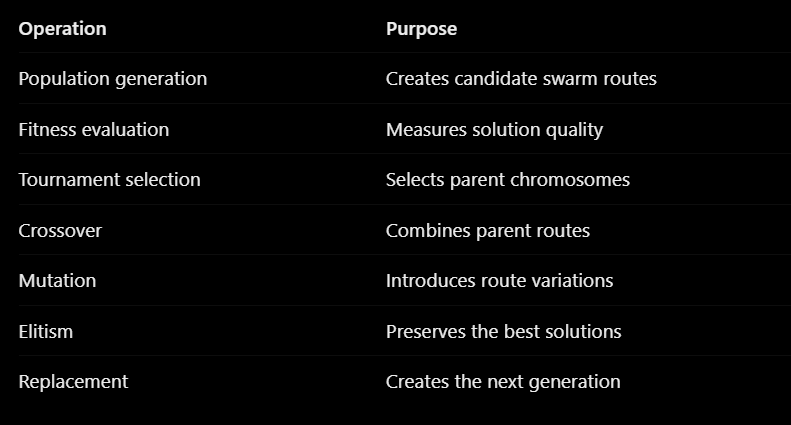

Why do we use elitism?

Suppose the best chromosome in Generation 20 has a fitness of 500. If we don't preserve it, the next generation might accidentally lose that solution.

Elitism carries the best two chromosomes into the next generation.

# Stage 6 Analyze GA results
# 19.Plot convergence graph

This graph shows how the best fitenss changes over successive generations

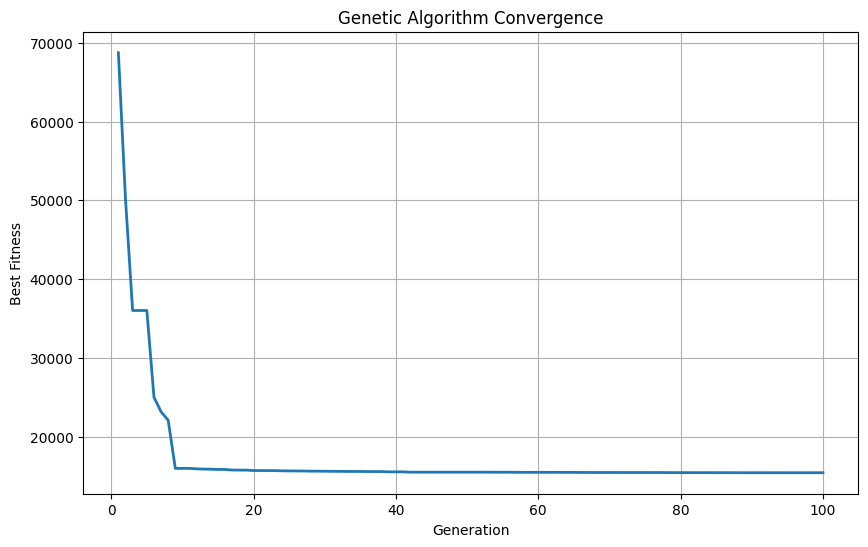

In [21]:
# ============================================
# CELL 19: GA CONVERGENCE GRAPH
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(fitness_history) + 1),
    fitness_history,
    linewidth=2
)

plt.xlabel("Generation")
plt.ylabel("Best Fitness")

plt.title("Genetic Algorithm Convergence")

plt.grid(True)

plt.show()

- X-axis represents generations.



- Y-axis represents the best fitness value.



- A decreasing curve indicates improvement.



- A flat curve indicates that the best solution is no longer improving.

# 20.Visualize optimized UAV routes

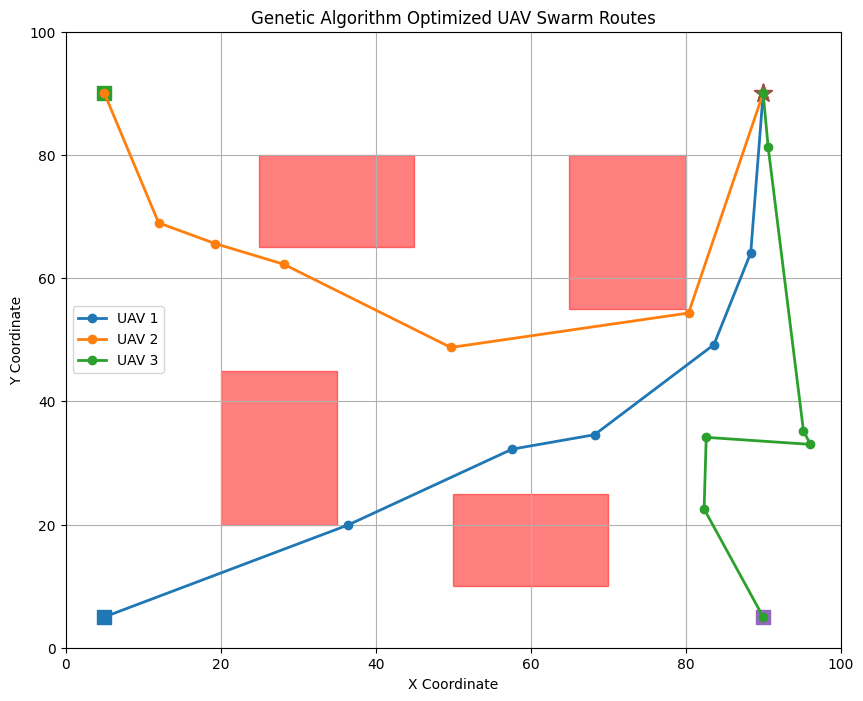

In [22]:
# ============================================
# CELL 20: OPTIMIZED ROUTE VISUALIZATION
# ============================================

plt.figure(figsize=(10, 8))

# Draw obstacles
for x, y, width, height in obstacles:

    rectangle = plt.Rectangle(
        (x, y),
        width,
        height,
        color="red",
        alpha=0.5
    )

    plt.gca().add_patch(rectangle)


# Draw optimized routes
for i, route in enumerate(best_solution):

    plt.plot(
        route[:, 0],
        route[:, 1],
        marker="o",
        linewidth=2,
        label=f"UAV {i + 1}"
    )

    plt.scatter(
        route[0, 0],
        route[0, 1],
        marker="s",
        s=100
    )

    plt.scatter(
        route[-1, 0],
        route[-1, 1],
        marker="*",
        s=180
    )


plt.xlim(0, MAP_WIDTH)
plt.ylim(0, MAP_HEIGHT)

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.title("Genetic Algorithm Optimized UAV Swarm Routes")

plt.legend()
plt.grid(True)

plt.show()

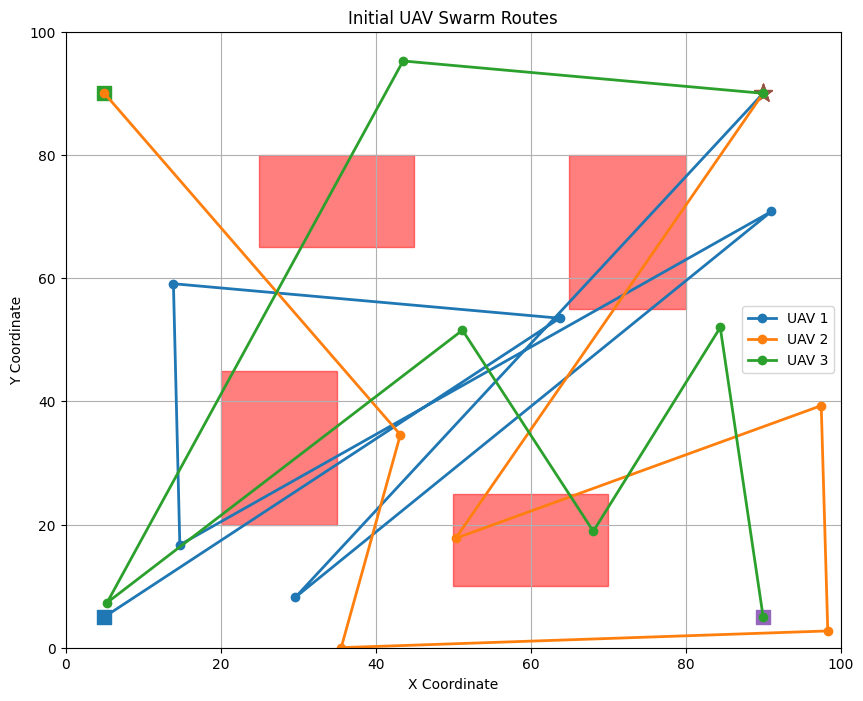

# 21.Compare iniital and optimized results

In [23]:
# ============================================
# CELL 21: INITIAL VS OPTIMIZED COMPARISON
# ============================================

initial_distance = sum(
    calculate_path_length(route)
    for route in initial_routes
)

optimized_distance = sum(
    calculate_path_length(route)
    for route in best_solution
)

initial_obstacle_penalty = sum(
    calculate_obstacle_penalty(route)
    for route in initial_routes
)

optimized_obstacle_penalty = sum(
    calculate_obstacle_penalty(route)
    for route in best_solution
)

initial_separation_penalty = (
    calculate_swarm_separation_penalty(initial_routes)
)

optimized_separation_penalty = (
    calculate_swarm_separation_penalty(best_solution)
)

print("INITIAL VS OPTIMIZED RESULTS")
print("-----------------------------------")

print(f"Initial Total Distance: {initial_distance:.2f}")
print(f"Optimized Total Distance: {optimized_distance:.2f}")

print(f"\nInitial Obstacle Penalty: {initial_obstacle_penalty}")
print(f"Optimized Obstacle Penalty: {optimized_obstacle_penalty}")

print(f"\nInitial Separation Penalty: {initial_separation_penalty:.2f}")
print(f"Optimized Separation Penalty: {optimized_separation_penalty:.2f}")

print(f"\nInitial Fitness: {initial_fitness:.2f}")
print(f"Optimized Fitness: {best_fitness:.2f}")

INITIAL VS OPTIMIZED RESULTS
-----------------------------------
Initial Total Distance: 1018.58
Optimized Total Distance: 367.87

Initial Obstacle Penalty: 69
Optimized Obstacle Penalty: 0

Initial Separation Penalty: 300.00
Optimized Separation Penalty: 300.00

Initial Fitness: 85156.97
Optimized Fitness: 15413.20


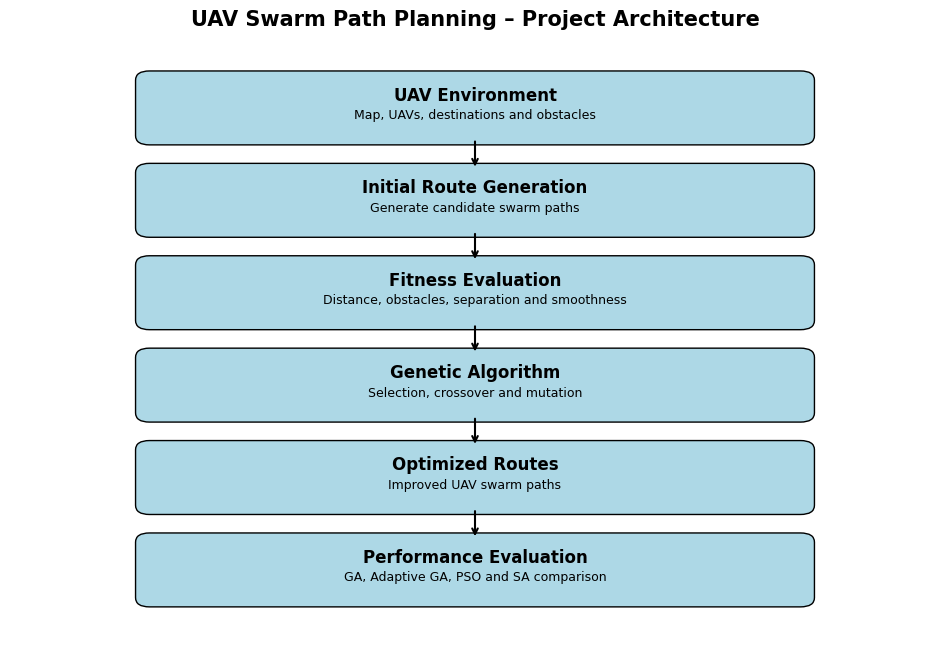

In [24]:
# ============================================
# CELL 22: PROJECT ARCHITECTURE DIAGRAM
# ============================================

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 8))

steps = [
    ("UAV Environment", "Map, UAVs, destinations and obstacles"),
    ("Initial Route Generation", "Generate candidate swarm paths"),
    ("Fitness Evaluation", "Distance, obstacles, separation and smoothness"),
    ("Genetic Algorithm", "Selection, crossover and mutation"),
    ("Optimized Routes", "Improved UAV swarm paths"),
    ("Performance Evaluation", "GA, Adaptive GA, PSO and SA comparison")
]

y_positions = [0.88, 0.73, 0.58, 0.43, 0.28, 0.13]

for i, (heading, description) in enumerate(steps):

    box = FancyBboxPatch(
        (0.15, y_positions[i] - 0.045),
        0.7,
        0.09,
        boxstyle="round,pad=0.015",
        edgecolor="black",
        facecolor="lightblue"
    )

    ax.add_patch(box)

    ax.text(
        0.5,
        y_positions[i] + 0.012,
        heading,
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

    ax.text(
        0.5,
        y_positions[i] - 0.018,
        description,
        ha="center",
        fontsize=9
    )

    if i < len(steps) - 1:

        ax.annotate(
            "",
            xy=(0.5, y_positions[i + 1] + 0.05),
            xytext=(0.5, y_positions[i] - 0.05),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

plt.title(
    "UAV Swarm Path Planning – Project Architecture",
    fontsize=15,
    fontweight="bold"
)

plt.show()

# now the baseline GA and initial performace evaluation is done
# next - improve the swarm separaation model and validate routes

# 23.Assign different destionatons to each UAV(A)

Give each UAV a separate destination and regenerate its initial routes and population.

In [25]:
# Assign a different destination to each UAV

goal_positions = np.array([
    [90, 90],   # UAV 1 destination
    [90, 50],   # UAV 2 destination
    [50, 90]    # UAV 3 destination
], dtype=float)

print("Updated UAV destinations:")

for i in range(NUM_UAVS):
    print(f"UAV {i + 1}:")
    print("Start:", start_positions[i])
    print("Goal: ", goal_positions[i])

Updated UAV destinations:
UAV 1:
Start: [5. 5.]
Goal:  [90. 90.]
UAV 2:
Start: [ 5. 90.]
Goal:  [90. 50.]
UAV 3:
Start: [90.  5.]
Goal:  [50. 90.]


# 24.Regenerate initial routes

In [26]:
# Generate new initial routes for all UAVs

initial_routes = []

for i in range(NUM_UAVS):
    route = generate_random_route(
        start_positions[i],
        goal_positions[i],
        num_waypoints=5
    )

    initial_routes.append(route)

print("New initial routes generated successfully!")

New initial routes generated successfully!


# 25.Improve collision/separation evaluation

Compare UAV positions at the same simulated time instead of simply comparing corresponding waypoint indices.

Every UAV flies at a constant speed.



Each UAV follows its generated route.



Once a UAV reaches its destination, it stays there.



If two UAVs come closer than the minimum safe separation, we add a penalty.

In [27]:
# synchronized UAV separation evaluation
# Minimum safe distance between two UAVs
MIN_SEPARATION = 10.0

# Simulation settings
UAV_SPEED = 10.0       # Map units per second
TIME_STEP = 0.5        # Check positions every 0.5 seconds


def get_uav_position_at_time(route, time):
    """
    Calculate a UAV's position at a particular simulation time.
    Assumes constant speed and stops the UAV at its destination.
    """

    route = np.array(route, dtype=float)

    # Calculate distance of every route segment
    segment_lengths = np.linalg.norm(
        np.diff(route, axis=0), axis=1
    )

    # Total distance travelled along the route
    total_distance = np.sum(segment_lengths)

    # Distance travelled by the UAV at the given time
    distance_to_travel = UAV_SPEED * time

    # If the UAV has reached its destination, keep it there
    if distance_to_travel >= total_distance:
        return route[-1]

    # Find the segment containing the UAV
    cumulative_distance = 0.0

    for i, segment_length in enumerate(segment_lengths):

        if cumulative_distance + segment_length >= distance_to_travel:

            distance_on_segment = distance_to_travel - cumulative_distance

            if segment_length == 0:
                return route[i]

            ratio = distance_on_segment / segment_length

            position = (
                route[i] +
                ratio * (route[i + 1] - route[i])
            )

            return position

        cumulative_distance += segment_length

    return route[-1]


def evaluate_swarm_separation(routes):

    # Calculate the travel time required by each UAV
    travel_times = [
        calculate_path_length(route) / UAV_SPEED
        for route in routes
    ]

    # Simulate until the slowest UAV reaches its destination
    max_time = max(travel_times)

    simulation_times = np.arange(
        0, max_time + TIME_STEP, TIME_STEP
    )

    total_penalty = 0
    violation_count = 0
    minimum_distance = float("inf")
    total_checks = 0

    # Compare every UAV pair at the same simulation time
    for time in simulation_times:

        positions = [
            get_uav_position_at_time(route, time)
            for route in routes
        ]

        for i in range(len(positions)):
            for j in range(i + 1, len(positions)):

                distance = np.linalg.norm(
                    positions[i] - positions[j]
                )

                total_checks += 1
                minimum_distance = min(minimum_distance, distance)

                if distance < MIN_SEPARATION:

                    violation_count += 1

                    # Penalize the amount of separation violation
                    total_penalty += (
                        MIN_SEPARATION - distance
                    ) ** 2

    # Average penalty to keep its scale manageable
    if total_checks > 0:
        average_penalty = total_penalty / total_checks
    else:
        average_penalty = 0

    return {
        "penalty": average_penalty,
        "violations": violation_count,
        "minimum_distance": minimum_distance,
        "total_checks": total_checks
    }


def calculate_swarm_separation_penalty(routes):

    report = evaluate_swarm_separation(routes)

    return report["penalty"]


print("Synchronized UAV separation evaluation implemented!")

Synchronized UAV separation evaluation implemented!


In [28]:
separation_report = evaluate_swarm_separation(initial_routes)

print("INITIAL SWARM SEPARATION REPORT")
print("--------------------------------")

print("Minimum distance between UAVs:",
      round(separation_report["minimum_distance"], 2))

print("Separation violations:",
      separation_report["violations"])

print("Total position comparisons:",
      separation_report["total_checks"])

print("Average separation penalty:",
      round(separation_report["penalty"], 2))

INITIAL SWARM SEPARATION REPORT
--------------------------------
Minimum distance between UAVs: 8.57
Separation violations: 4
Total position comparisons: 258
Average separation penalty: 0.02


# we need to update the swarm fitness functions to use our new separation evalaution

In [29]:
# Updated fitness weights

W_DISTANCE = 1.0
W_OBSTACLE = 1000.0
W_SEPARATION = 500.0
W_SMOOTHNESS = 5.0


def calculate_swarm_fitness(routes):

    total_distance = 0
    total_obstacle_penalty = 0
    total_smoothness = 0

    for route in routes:

        total_distance += calculate_path_length(route)

        total_obstacle_penalty += calculate_obstacle_penalty(route)

        total_smoothness += calculate_smoothness(route)

    # New synchronized separation penalty
    separation_report = evaluate_swarm_separation(routes)

    separation_penalty = separation_report["penalty"]

    fitness = (
        W_DISTANCE * total_distance
        + W_OBSTACLE * total_obstacle_penalty
        + W_SEPARATION * separation_penalty
        + W_SMOOTHNESS * total_smoothness
    )

    return fitness


print("Updated swarm fitness function successfully!")

Updated swarm fitness function successfully!


# 26.Re-run basline GA Check whether the optimized routes reduce distance, obstacle collisions and separation violations.

## Regenerate the population with the updated fitness function

In [30]:
# Generate a fresh population using the updated fitness function

population = generate_population(POPULATION_SIZE)

print("New population generated!")
print("Population size:", len(population))

print("Initial population best fitness:",
      round(min(calculate_swarm_fitness(chromosome)
                for chromosome in population), 2))

New population generated!
Population size: 50
Initial population best fitness: 56232.62


## Run baseline GA again

In [31]:
# Run baseline Genetic Algorithm

best_solution, best_fitness, fitness_history = genetic_algorithm()

print("\nBASELINE GA RESULTS")
print("-------------------")

print("Best Fitness:", round(best_fitness, 2))
print("Initial Fitness:", round(fitness_history[0], 2))
print("Final Fitness:", round(fitness_history[-1], 2))


BASELINE GA RESULTS
-------------------
Best Fitness: 476.63
Initial Fitness: 45503.49
Final Fitness: 476.63


## Comapare distance, obstacle penalty, separation violations and fitness

In [32]:
# Evaluate optimized swarm separation

optimized_separation = evaluate_swarm_separation(best_solution)

print("\nOPTIMIZED SWARM SEPARATION")
print("--------------------------")

print("Minimum Distance:",
      round(optimized_separation["minimum_distance"], 2))

print("Separation Violations:",
      optimized_separation["violations"])

print("Average Separation Penalty:",
      round(optimized_separation["penalty"], 2))


OPTIMIZED SWARM SEPARATION
--------------------------
Minimum Distance: 12.14
Separation Violations: 0
Average Separation Penalty: 0.0


In [33]:
# Compare initial and optimized swarm performance

initial_distance = sum(
    calculate_path_length(route)
    for route in initial_routes
)

optimized_distance = sum(
    calculate_path_length(route)
    for route in best_solution
)

initial_obstacle_penalty = sum(
    calculate_obstacle_penalty(route)
    for route in initial_routes
)

optimized_obstacle_penalty = sum(
    calculate_obstacle_penalty(route)
    for route in best_solution
)

initial_separation = evaluate_swarm_separation(initial_routes)
optimized_separation = evaluate_swarm_separation(best_solution)

print("\nINITIAL VS OPTIMIZED PERFORMANCE")
print("--------------------------------")

print("Initial Distance:", round(initial_distance, 2))
print("Optimized Distance:", round(optimized_distance, 2))

print("\nInitial Obstacle Penalty:",
      initial_obstacle_penalty)

print("Optimized Obstacle Penalty:",
      optimized_obstacle_penalty)

print("\nInitial Separation Violations:",
      initial_separation["violations"])

print("Optimized Separation Violations:",
      optimized_separation["violations"])

print("\nInitial Fitness:",
      round(calculate_swarm_fitness(initial_routes), 2))

print("Optimized Fitness:",
      round(best_fitness, 2))


INITIAL VS OPTIMIZED PERFORMANCE
--------------------------------
Initial Distance: 1083.16
Optimized Distance: 414.88

Initial Obstacle Penalty: 78
Optimized Obstacle Penalty: 0

Initial Separation Violations: 4
Optimized Separation Violations: 0

Initial Fitness: 79264.88
Optimized Fitness: 476.63


## Reduction in total travel distance : 61.07%

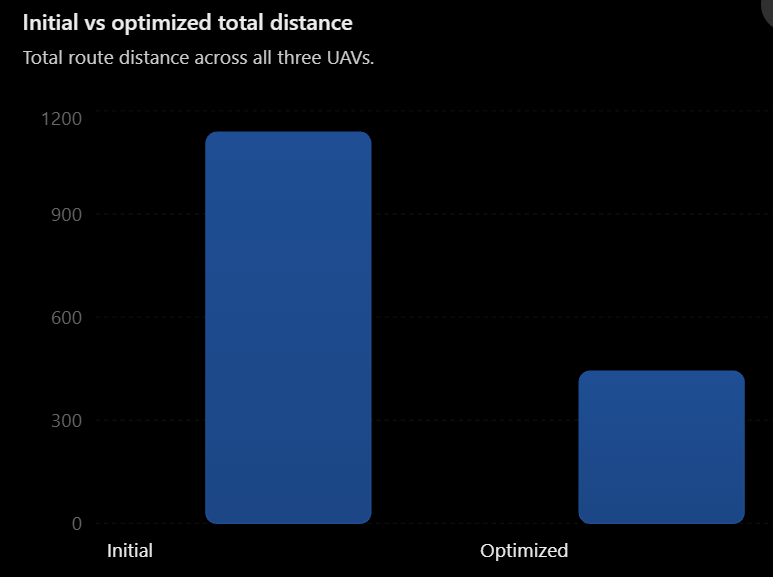

# 27. Implement Adaptive Genetic Algorithm

Adapt mutation and crossover rates during optimization to improve the search process.

## Dynamically adjust mutation and crossover rates

In [34]:
# Adaptive Genetic Algorithm parameters

ADAPTIVE_GENERATIONS = 100

MAX_MUTATION_RATE = 0.30
MIN_MUTATION_RATE = 0.05

MAX_CROSSOVER_RATE = 0.95
MIN_CROSSOVER_RATE = 0.65

MAX_MUTATION_STRENGTH = 8.0
MIN_MUTATION_STRENGTH = 1.0

print("Adaptive GA parameters initialized!")

Adaptive GA parameters initialized!


In [35]:
def get_adaptive_parameters(generation):

    progress = generation / ADAPTIVE_GENERATIONS

    # Mutation decreases as generations progress
    mutation_rate = (
        MAX_MUTATION_RATE
        - progress * (MAX_MUTATION_RATE - MIN_MUTATION_RATE)
    )

    # Crossover increases gradually
    crossover_rate = (
        MIN_CROSSOVER_RATE
        + progress * (MAX_CROSSOVER_RATE - MIN_CROSSOVER_RATE)
    )

    # Mutation strength also decreases
    mutation_strength = (
        MAX_MUTATION_STRENGTH
        - progress * (MAX_MUTATION_STRENGTH - MIN_MUTATION_STRENGTH)
    )

    return mutation_rate, crossover_rate, mutation_strength


print("Adaptive parameter calculation implemented!")

# Test the parameter changes

for generation in [0, 25, 50, 75, 100]:

    mutation, crossover, strength = get_adaptive_parameters(generation)

    print(
        f"Generation {generation}: "
        f"Mutation={mutation:.3f}, "
        f"Crossover={crossover:.3f}, "
        f"Mutation Strength={strength:.2f}"
    )

Adaptive parameter calculation implemented!
Generation 0: Mutation=0.300, Crossover=0.650, Mutation Strength=8.00
Generation 25: Mutation=0.237, Crossover=0.725, Mutation Strength=6.25
Generation 50: Mutation=0.175, Crossover=0.800, Mutation Strength=4.50
Generation 75: Mutation=0.112, Crossover=0.875, Mutation Strength=2.75
Generation 100: Mutation=0.050, Crossover=0.950, Mutation Strength=1.00


Beginning: High mutation helps explore different routes.



Later: Low mutation helps preserve good routes.



Crossover: Gradually increases to combine good solutions more frequently

In [36]:
# implement Adaptive Mutation
def adaptive_mutate(chromosome, mutation_rate, mutation_strength):

    mutated_chromosome = copy.deepcopy(chromosome)

    for route in mutated_chromosome:

        for i in range(1, len(route) - 1):

            if random.random() < mutation_rate:

                route[i][0] += random.gauss(0, mutation_strength)
                route[i][1] += random.gauss(0, mutation_strength)

                route[i][0] = np.clip(route[i][0], 0, MAP_WIDTH)
                route[i][1] = np.clip(route[i][1], 0, MAP_HEIGHT)

    return mutated_chromosome


print("Adaptive mutation implemented!")

Adaptive mutation implemented!


Cell 27D – Implement Adaptive Genetic Algorithm
This algorithm uses:
- Tournament selection.
- Adaptive crossover rate.
- Adaptive mutation rate.
- Adaptive mutation strength.
- Elitism.
- Our updated swarm fitness function.

In [37]:
def adaptive_genetic_algorithm():

    population = generate_population(POPULATION_SIZE)

    best_solution = None
    best_fitness = float("inf")

    fitness_history = []
    mutation_history = []
    crossover_history = []

    for generation in range(ADAPTIVE_GENERATIONS):

        mutation_rate, crossover_rate, mutation_strength = (
            get_adaptive_parameters(generation)
        )

        fitness_scores = [
            calculate_swarm_fitness(chromosome)
            for chromosome in population
        ]

        sorted_population = [
            chromosome for _, chromosome in sorted(
                zip(fitness_scores, population),
                key=lambda item: item[0]
            )
        ]

        current_best_fitness = min(fitness_scores)

        if current_best_fitness < best_fitness:

            best_fitness = current_best_fitness

            best_solution = copy.deepcopy(
                sorted_population[0]
            )

        fitness_history.append(best_fitness)

        mutation_history.append(mutation_rate)
        crossover_history.append(crossover_rate)

        # Preserve elite individuals
        new_population = [
            copy.deepcopy(individual)
            for individual in sorted_population[:ELITISM_COUNT]
        ]

        while len(new_population) < POPULATION_SIZE:

            parent1 = tournament_selection(population)
            parent2 = tournament_selection(population)

            # Adaptive crossover
            if random.random() < crossover_rate:

                child1, child2 = crossover(parent1, parent2)

            else:

                child1 = copy.deepcopy(parent1)
                child2 = copy.deepcopy(parent2)

            # Adaptive mutation
            child1 = adaptive_mutate(
                child1,
                mutation_rate,
                mutation_strength
            )

            child2 = adaptive_mutate(
                child2,
                mutation_rate,
                mutation_strength
            )

            new_population.append(child1)

            if len(new_population) < POPULATION_SIZE:
                new_population.append(child2)

        population = new_population

        if (generation + 1) % 20 == 0:

            print(
                f"Generation {generation + 1}/{ADAPTIVE_GENERATIONS} "
                f"| Best Fitness: {best_fitness:.2f} "
                f"| Mutation: {mutation_rate:.3f} "
                f"| Crossover: {crossover_rate:.3f}"
            )

    return (
        best_solution,
        best_fitness,
        fitness_history,
        mutation_history,
        crossover_history
    )


print("Adaptive Genetic Algorithm implemented!")

Adaptive Genetic Algorithm implemented!


In [38]:
def crossover(parent1, parent2):

    child1 = copy.deepcopy(parent1)
    child2 = copy.deepcopy(parent2)

    for uav in range(len(parent1)):

        for i in range(1, len(parent1[uav]) - 1):

            if random.random() < 0.5:

                child1[uav][i] = parent2[uav][i].copy()
                child2[uav][i] = parent1[uav][i].copy()

    return child1, child2


print("Crossover function restored!")

Crossover function restored!


In [39]:
adaptive_solution, adaptive_fitness, adaptive_history, mutation_history, crossover_history = (
    adaptive_genetic_algorithm()
)

print("\nADAPTIVE GA COMPLETED")
print("---------------------")

print("Best Fitness:", round(adaptive_fitness, 2))
print("Initial Fitness:", round(adaptive_history[0], 2))
print("Final Fitness:", round(adaptive_history[-1], 2))

Generation 20/100 | Best Fitness: 811.54 | Mutation: 0.253 | Crossover: 0.707
Generation 40/100 | Best Fitness: 616.71 | Mutation: 0.202 | Crossover: 0.767
Generation 60/100 | Best Fitness: 515.66 | Mutation: 0.152 | Crossover: 0.827
Generation 80/100 | Best Fitness: 456.02 | Mutation: 0.102 | Crossover: 0.887
Generation 100/100 | Best Fitness: 438.31 | Mutation: 0.052 | Crossover: 0.947

ADAPTIVE GA COMPLETED
---------------------
Best Fitness: 438.31
Initial Fitness: 50510.92
Final Fitness: 438.31


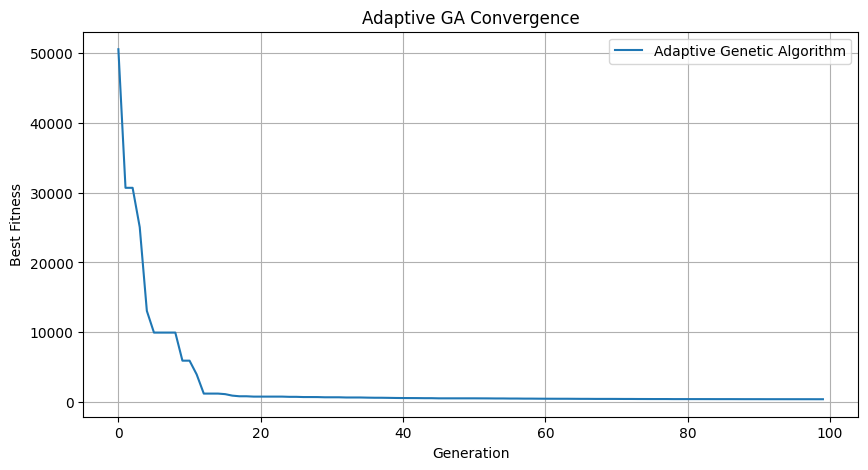

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(
    adaptive_history,
    label="Adaptive Genetic Algorithm"
)

plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.title("Adaptive GA Convergence")
plt.legend()
plt.grid(True)

plt.show()

## Compare convergence against baseline GA

# 27G - Evaluate Adaptive GA results


In [41]:
# Evaluate Adaptive GA solution

adaptive_distance = sum(
    calculate_path_length(route)
    for route in adaptive_solution
)

adaptive_obstacle_penalty = sum(
    calculate_obstacle_penalty(route)
    for route in adaptive_solution
)

adaptive_separation = evaluate_swarm_separation(
    adaptive_solution
)

print("ADAPTIVE GA PERFORMANCE")
print("-----------------------")

print("Best Fitness:", round(adaptive_fitness, 2))

print("Total Distance:", round(adaptive_distance, 2))

print("Obstacle Penalty:", adaptive_obstacle_penalty)

print("Minimum UAV Separation:",
      round(adaptive_separation["minimum_distance"], 2))

print("Separation Violations:",
      adaptive_separation["violations"])

print("Average Separation Penalty:",
      round(adaptive_separation["penalty"], 2))

ADAPTIVE GA PERFORMANCE
-----------------------
Best Fitness: 438.31
Total Distance: 405.5
Obstacle Penalty: 0
Minimum UAV Separation: 9.55
Separation Violations: 3
Average Separation Penalty: 0.0


# 27H - Compare baseline GA and Adaptive GA

In [42]:
# Compare the two algorithms

print("BASELINE GA vs ADAPTIVE GA")
print("--------------------------")

print("Baseline GA Fitness:",
      round(best_fitness, 2))

print("Adaptive GA Fitness:",
      round(adaptive_fitness, 2))

print("Baseline GA Distance:",
      round(optimized_distance, 2))

print("Adaptive GA Distance:",
      round(adaptive_distance, 2))

BASELINE GA vs ADAPTIVE GA
--------------------------
Baseline GA Fitness: 476.63
Adaptive GA Fitness: 438.31
Baseline GA Distance: 414.88
Adaptive GA Distance: 405.5


# 28.Add dynamic obstacles

Introduce moving obstacles and test how the UAV swarm replans its paths.

- Moving obstacles with defined velocities.



- Visualization of their movement.



- Time-based collision detection between UAVs and moving obstacles.



- Replanning using Genetic Algorithm.

# 28A Define moving obstacles

In [43]:
# Define dynamic obstacles

dynamic_obstacles = [
    {
        "x": 10.0,
        "y": 45.0,
        "width": 10.0,
        "height": 10.0,
        "vx": 3.0,
        "vy": 1.5
    },
    {
        "x": 70.0,
        "y": 20.0,
        "width": 12.0,
        "height": 10.0,
        "vx": -2.0,
        "vy": 2.5
    }
]

print("Dynamic obstacles initialized!")

for i, obstacle in enumerate(dynamic_obstacles):
    print(f"Obstacle {i + 1}: {obstacle}")

Dynamic obstacles initialized!
Obstacle 1: {'x': 10.0, 'y': 45.0, 'width': 10.0, 'height': 10.0, 'vx': 3.0, 'vy': 1.5}
Obstacle 2: {'x': 70.0, 'y': 20.0, 'width': 12.0, 'height': 10.0, 'vx': -2.0, 'vy': 2.5}


# 28B - Calculate moving obstacle positions
This function makes obstacles bounce off the map boundaries instead of leaving the environment.

In [44]:
def reflected_position(initial_position, velocity, time, maximum):

    if maximum <= 0:
        return 0.0

    period = 2 * maximum

    position = (
        initial_position + velocity * time
    ) % period

    if position > maximum:
        position = period - position

    return position


def get_dynamic_obstacle_position(obstacle, time):

    x = reflected_position(
        obstacle["x"],
        obstacle["vx"],
        time,
        MAP_WIDTH - obstacle["width"]
    )

    y = reflected_position(
        obstacle["y"],
        obstacle["vy"],
        time,
        MAP_HEIGHT - obstacle["height"]
    )

    return (
        x,
        y,
        obstacle["width"],
        obstacle["height"]
    )


print("Dynamic obstacle movement function implemented!")

Dynamic obstacle movement function implemented!


# 28C - Visualize moving obstacles

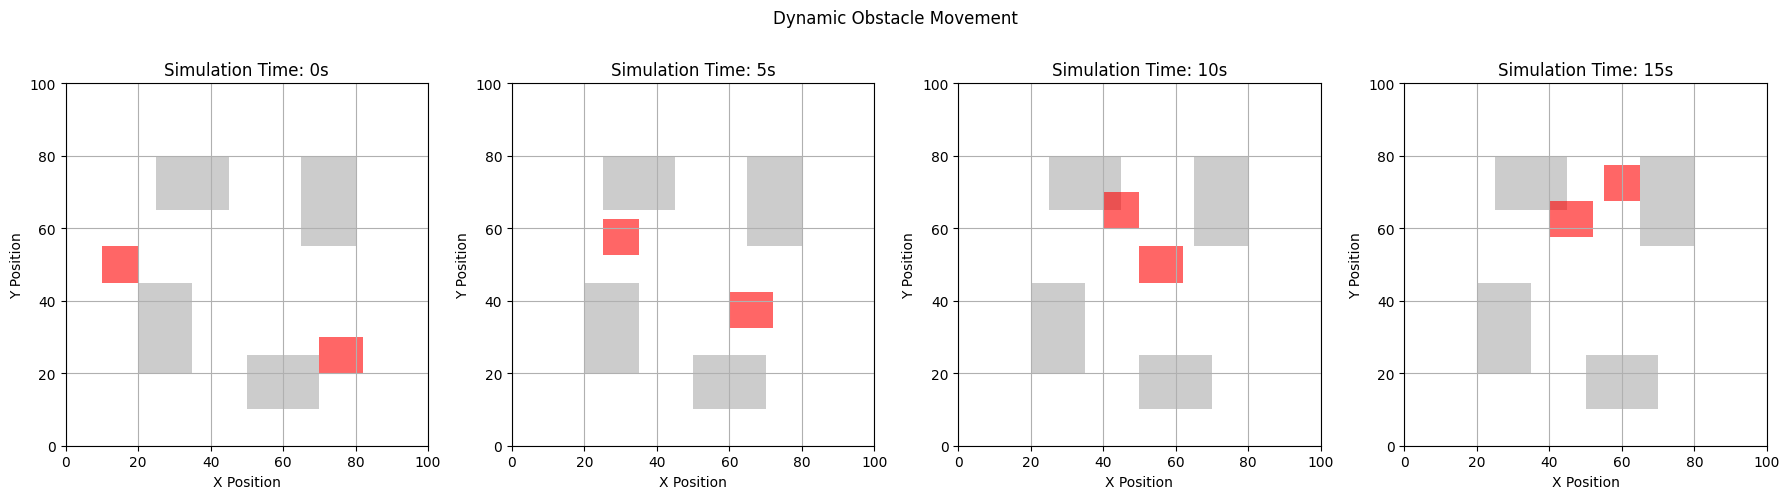

In [45]:
from matplotlib.patches import Rectangle

times_to_display = [0, 5, 10, 15]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, time in zip(axes, times_to_display):

    ax.set_xlim(0, MAP_WIDTH)
    ax.set_ylim(0, MAP_HEIGHT)
    ax.set_aspect("equal")

    ax.set_title(f"Simulation Time: {time}s")
    ax.set_xlabel("X Position")
    ax.set_ylabel("Y Position")

    # Static obstacles
    for x, y, w, h in obstacles:
        ax.add_patch(
            Rectangle(
                (x, y), w, h,
                facecolor="gray",
                alpha=0.4
            )
        )

    # Dynamic obstacles
    for obstacle in dynamic_obstacles:

        x, y, w, h = get_dynamic_obstacle_position(
            obstacle, time
        )

        ax.add_patch(
            Rectangle(
                (x, y), w, h,
                facecolor="red",
                alpha=0.6
            )
        )

    ax.grid(True)

plt.suptitle("Dynamic Obstacle Movement")
plt.tight_layout()
plt.show()

# 28D - Detect Collisions with moving obstacles

In [46]:
def evaluate_dynamic_obstacle_collisions(routes):

    travel_times = [
        calculate_path_length(route) / UAV_SPEED
        for route in routes
    ]

    max_time = max(travel_times)

    simulation_times = np.arange(
        0, max_time + TIME_STEP, TIME_STEP
    )

    collision_count = 0
    total_checks = 0

    for time in simulation_times:

        for route in routes:

            uav_position = get_uav_position_at_time(
                route, time
            )

            for obstacle in dynamic_obstacles:

                obstacle_position = get_dynamic_obstacle_position(
                    obstacle, time
                )

                total_checks += 1

                if point_inside_obstacle(
                    uav_position, obstacle_position
                ):
                    collision_count += 1

    return {
        "collisions": collision_count,
        "total_checks": total_checks
    }


# Test using the Adaptive GA solution

dynamic_report = evaluate_dynamic_obstacle_collisions(
    adaptive_solution
)

print("DYNAMIC OBSTACLE COLLISION REPORT")
print("---------------------------------")

print("Detected collisions:",
      dynamic_report["collisions"])

print("Total checks:",
      dynamic_report["total_checks"])

DYNAMIC OBSTACLE COLLISION REPORT
---------------------------------
Detected collisions: 3
Total checks: 228


# 28E - Include dynamic obstacles in fitness

In [47]:
W_DYNAMIC_OBSTACLE = 1000.0


def calculate_swarm_fitness(routes):

    total_distance = sum(
        calculate_path_length(route)
        for route in routes
    )

    static_obstacle_penalty = sum(
        calculate_obstacle_penalty(route)
        for route in routes
    )

    smoothness_penalty = sum(
        calculate_smoothness(route)
        for route in routes
    )

    separation_report = evaluate_swarm_separation(routes)

    dynamic_report = evaluate_dynamic_obstacle_collisions(routes)

    fitness = (
        W_DISTANCE * total_distance
        + W_OBSTACLE * static_obstacle_penalty
        + W_SEPARATION * separation_report["penalty"]
        + W_SMOOTHNESS * smoothness_penalty
        + W_DYNAMIC_OBSTACLE * dynamic_report["collisions"]
    )

    return fitness


print("Dynamic obstacle penalty added to swarm fitness!")

Dynamic obstacle penalty added to swarm fitness!


# 28F - Replan routes using Adaptive GA

In [48]:
(
    dynamic_solution,
    dynamic_fitness,
    dynamic_history,
    dynamic_mutation_history,
    dynamic_crossover_history
) = adaptive_genetic_algorithm()

print("\nDYNAMIC ENVIRONMENT OPTIMIZATION")
print("--------------------------------")

print("Best Fitness:", round(dynamic_fitness, 2))

dynamic_final_report = evaluate_dynamic_obstacle_collisions(
    dynamic_solution
)

print("Dynamic Obstacle Collisions:",
      dynamic_final_report["collisions"])

print("Separation Violations:",
      evaluate_swarm_separation(dynamic_solution)["violations"])

Generation 20/100 | Best Fitness: 1021.36 | Mutation: 0.253 | Crossover: 0.707
Generation 40/100 | Best Fitness: 950.76 | Mutation: 0.202 | Crossover: 0.767
Generation 60/100 | Best Fitness: 861.40 | Mutation: 0.152 | Crossover: 0.827
Generation 80/100 | Best Fitness: 809.71 | Mutation: 0.102 | Crossover: 0.887
Generation 100/100 | Best Fitness: 783.13 | Mutation: 0.052 | Crossover: 0.947

DYNAMIC ENVIRONMENT OPTIMIZATION
--------------------------------
Best Fitness: 783.13
Dynamic Obstacle Collisions: 0
Separation Violations: 2


## re-evaluate routes and perform replannig

# 29.Implement PSO and Simulated Annealing

Compare the algorithms using common initial conditions and evaluation metrics.

# 29A - Particle Swarm Optimization(PSO)

In [49]:
# PSO parameters

PSO_PARTICLES = 20
PSO_ITERATIONS = 100

W_INERTIA = 0.7
C1 = 1.5
C2 = 1.5

def flatten_routes(routes):
    return np.concatenate([
        np.array(route[1:-1]).flatten()
        for route in routes
    ])


def rebuild_routes(position):
    routes = []

    index = 0

    for i in range(NUM_UAVS):

        route = [start_positions[i].copy()]

        for _ in range(5):

            x = position[index]
            y = position[index + 1]

            route.append(np.array([x, y]))

            index += 2

        route.append(goal_positions[i].copy())

        routes.append(np.array(route))

    return routes


def pso_algorithm():

    particles = [
        flatten_routes(generate_chromosome())
        for _ in range(PSO_PARTICLES)
    ]

    velocities = [
        np.random.uniform(-2, 2, len(particles[0]))
        for _ in range(PSO_PARTICLES)
    ]

    personal_best = [p.copy() for p in particles]

    personal_fitness = [
        calculate_swarm_fitness(rebuild_routes(p))
        for p in particles
    ]

    best_index = np.argmin(personal_fitness)

    global_best = personal_best[best_index].copy()
    global_fitness = personal_fitness[best_index]

    history = []

    for iteration in range(PSO_ITERATIONS):

        for i in range(PSO_PARTICLES):

            r1 = np.random.random(len(particles[i]))
            r2 = np.random.random(len(particles[i]))

            velocities[i] = (
                W_INERTIA * velocities[i]
                + C1 * r1 * (personal_best[i] - particles[i])
                + C2 * r2 * (global_best - particles[i])
            )

            particles[i] += velocities[i]

            particles[i] = np.clip(
                particles[i], 0, MAP_WIDTH
            )

            fitness = calculate_swarm_fitness(
                rebuild_routes(particles[i])
            )

            if fitness < personal_fitness[i]:

                personal_best[i] = particles[i].copy()
                personal_fitness[i] = fitness

            if fitness < global_fitness:

                global_best = particles[i].copy()
                global_fitness = fitness

        history.append(global_fitness)

        if (iteration + 1) % 20 == 0:
            print(
                f"PSO Iteration {iteration + 1}: "
                f"Fitness = {global_fitness:.2f}"
            )

    return rebuild_routes(global_best), global_fitness, history


print("PSO implemented!")

PSO implemented!


PSO_PARTICLES = 20: We have 20 candidate solutions.



PSO_ITERATIONS = 100: They improve their solutions over 100 iterations.



W_INERTIA = 0.7: Controls how much the particle continues in its previous direction.



C1 = 1.5: How much it is attracted towards its own best solution.



C2 = 1.5: How much it is attracted towards the overall best solution.

# 29B - Run PSO

In [50]:
pso_solution, pso_fitness, pso_history = pso_algorithm()

print("\nPSO RESULTS")
print("-----------")
print("Best Fitness:", round(pso_fitness, 2))

PSO Iteration 20: Fitness = 7457.32
PSO Iteration 40: Fitness = 7457.32
PSO Iteration 60: Fitness = 7457.32
PSO Iteration 80: Fitness = 7457.32
PSO Iteration 100: Fitness = 7457.32

PSO RESULTS
-----------
Best Fitness: 7457.32


# 29C - Simulated Annealing

In [51]:
# Simulated Annealing parameters

SA_ITERATIONS = 2000
INITIAL_TEMPERATURE = 1000
COOLING_RATE = 0.995


def simulated_annealing():

    current_solution = generate_chromosome()

    current_fitness = calculate_swarm_fitness(
        current_solution
    )

    best_solution = copy.deepcopy(current_solution)
    best_fitness = current_fitness

    temperature = INITIAL_TEMPERATURE
    history = []

    for iteration in range(SA_ITERATIONS):

        candidate = copy.deepcopy(current_solution)

        # Randomly modify one intermediate waypoint
        uav_index = random.randrange(NUM_UAVS)

        waypoint_index = random.randint(
            1, len(candidate[uav_index]) - 2
        )

        candidate[uav_index][waypoint_index] += np.random.normal(
            0, 5, size=2
        )

        candidate[uav_index][waypoint_index] = np.clip(
            candidate[uav_index][waypoint_index],
            0,
            MAP_WIDTH
        )

        candidate_fitness = calculate_swarm_fitness(candidate)

        difference = candidate_fitness - current_fitness

        if difference < 0 or (
            temperature > 0 and
            random.random() < math.exp(
                -difference / temperature
            )
        ):

            current_solution = candidate
            current_fitness = candidate_fitness

        if current_fitness < best_fitness:

            best_solution = copy.deepcopy(current_solution)
            best_fitness = current_fitness

        history.append(best_fitness)

        temperature *= COOLING_RATE

    return best_solution, best_fitness, history


print("Simulated Annealing implemented!")

Simulated Annealing implemented!


# 29D - Run simulatedd annealing

In [52]:
sa_solution, sa_fitness, sa_history = simulated_annealing()

print("\nSIMULATED ANNEALING RESULTS")
print("--------------------------")

print("Best Fitness:", round(sa_fitness, 2))


SIMULATED ANNEALING RESULTS
--------------------------
Best Fitness: 7791.41


# 29E - Compare all four Algorithms

In [53]:
algorithm_results = {
    "Baseline GA": best_fitness,
    "Adaptive GA": adaptive_fitness,
    "PSO": pso_fitness,
    "Simulated Annealing": sa_fitness
}

print("\nALGORITHM COMPARISON")
print("--------------------")

for algorithm, fitness in algorithm_results.items():

    print(f"{algorithm}: {fitness:.2f}")


ALGORITHM COMPARISON
--------------------
Baseline GA: 476.63
Adaptive GA: 438.31
PSO: 7457.32
Simulated Annealing: 7791.41


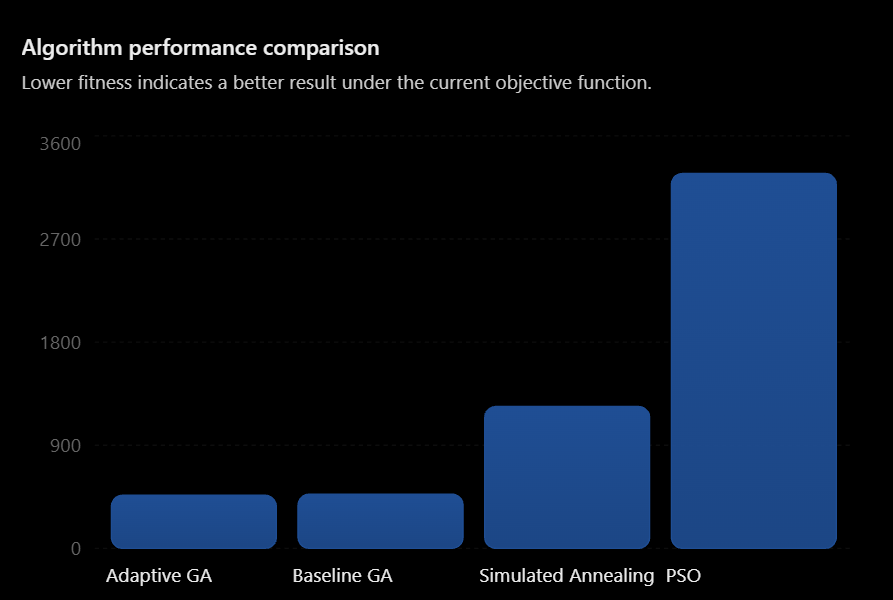

observation: Adaptive GA performs best in this run. PSO and Simulated Annealing have higher fitness, but this single-run comparison does not establish that they are inherently inferior. Their search representations and evaluation budgets differ.

One important detail: these four scores were obtained at different stages of the project. The baseline and Adaptive GA scores above use the earlier fitness setup, while the dynamic environment introduced an additional obstacle penalty. So we should label this as an initial algorithm comparison, not a fully controlled dynamic-environment benchmark.

## Implement both algorithms

## Compare their performance with GA and Adaptive GA

# 30.Final experiments and visualizations

# 30A - Re-evaluate GA and Adaptive GA

In [63]:
def mutate(chromosome):
    mutated_chromosome = copy.deepcopy(chromosome)

    for uav_index in range(NUM_UAVS):
        route = mutated_chromosome[uav_index]

        # Mutate only intermediate waypoints
        for waypoint_index in range(1, len(route) - 1):
            if random.random() < MUTATION_RATE:
                route[waypoint_index] += np.random.normal(
                    0, MUTATION_STRENGTH, size=2
                )

                route[waypoint_index] = np.clip(
                    route[waypoint_index], 0, MAP_WIDTH
                )

    return mutated_chromosome

In [55]:
test_chromosome = generate_chromosome()

print("Number of UAV routes:", len(test_chromosome))

for i, route in enumerate(test_chromosome):
    print(f"UAV {i+1}: {len(route)} points")

Number of UAV routes: 3
UAV 1: 7 points
UAV 2: 7 points
UAV 3: 7 points


In [56]:
test_population = generate_population(POPULATION_SIZE)

parent1 = test_population[0]
parent2 = test_population[1]

children = crossover(parent1, parent2)

print("Type of crossover output:", type(children))
print("Number of children:", len(children))
print("Type of first child:", type(children[0]))
print("Number of UAV routes:", len(children[0]))

Type of crossover output: <class 'tuple'>
Number of children: 2
Type of first child: <class 'list'>
Number of UAV routes: 3


In [57]:
baseline_dynamic_solution, baseline_dynamic_fitness, baseline_dynamic_history = (
    genetic_algorithm()
)

print("Baseline GA with dynamic fitness:",
      round(baseline_dynamic_fitness, 2))

(
    adaptive_dynamic_solution,
    adaptive_dynamic_fitness,
    adaptive_dynamic_history,
    adaptive_dynamic_mutation,
    adaptive_dynamic_crossover
) = adaptive_genetic_algorithm()

print("\nAdaptive GA with dynamic fitness:",
      round(adaptive_dynamic_fitness, 2))

Baseline GA with dynamic fitness: 2024.64
Generation 20/100 | Best Fitness: 1939.47 | Mutation: 0.253 | Crossover: 0.707
Generation 40/100 | Best Fitness: 911.26 | Mutation: 0.202 | Crossover: 0.767
Generation 60/100 | Best Fitness: 838.30 | Mutation: 0.152 | Crossover: 0.827
Generation 80/100 | Best Fitness: 772.68 | Mutation: 0.102 | Crossover: 0.887
Generation 100/100 | Best Fitness: 733.17 | Mutation: 0.052 | Crossover: 0.947

Adaptive GA with dynamic fitness: 733.17


# 30B - Final comparison

In [58]:
final_results = {
    "Baseline GA": baseline_dynamic_fitness,
    "Adaptive GA": adaptive_dynamic_fitness,
    "PSO": pso_fitness,
    "Simulated Annealing": sa_fitness
}

print("FINAL ALGORITHM COMPARISON")

for algorithm, fitness in sorted(
    final_results.items(),
    key=lambda item: item[1]
):
    print(f"{algorithm}: {fitness:.2f}")

FINAL ALGORITHM COMPARISON
Adaptive GA: 733.17
Baseline GA: 2024.64
PSO: 7457.32
Simulated Annealing: 7791.41


# 30C - Algorithm fitness comaprison

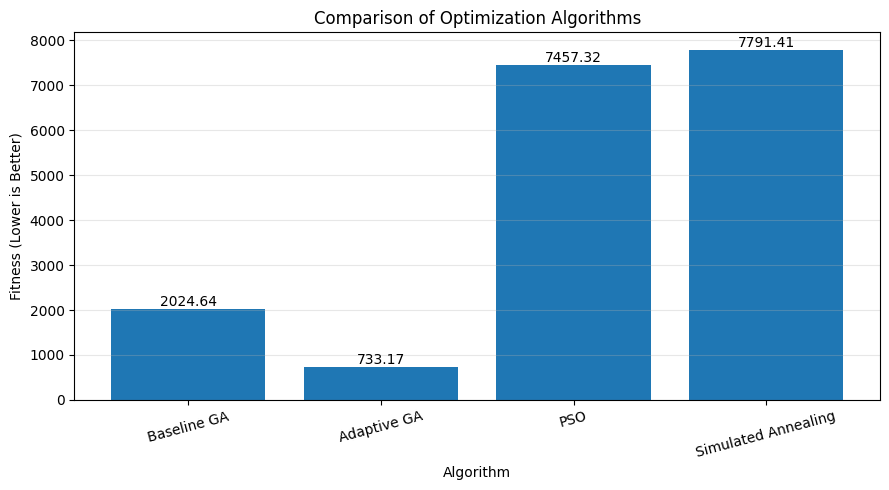

In [59]:
import matplotlib.pyplot as plt

algorithms = list(final_results.keys())
fitness_values = list(final_results.values())

plt.figure(figsize=(9, 5))
bars = plt.bar(algorithms, fitness_values)

plt.title("Comparison of Optimization Algorithms")
plt.xlabel("Algorithm")
plt.ylabel("Fitness (Lower is Better)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, fitness_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# 30D - Convergence Comaprison

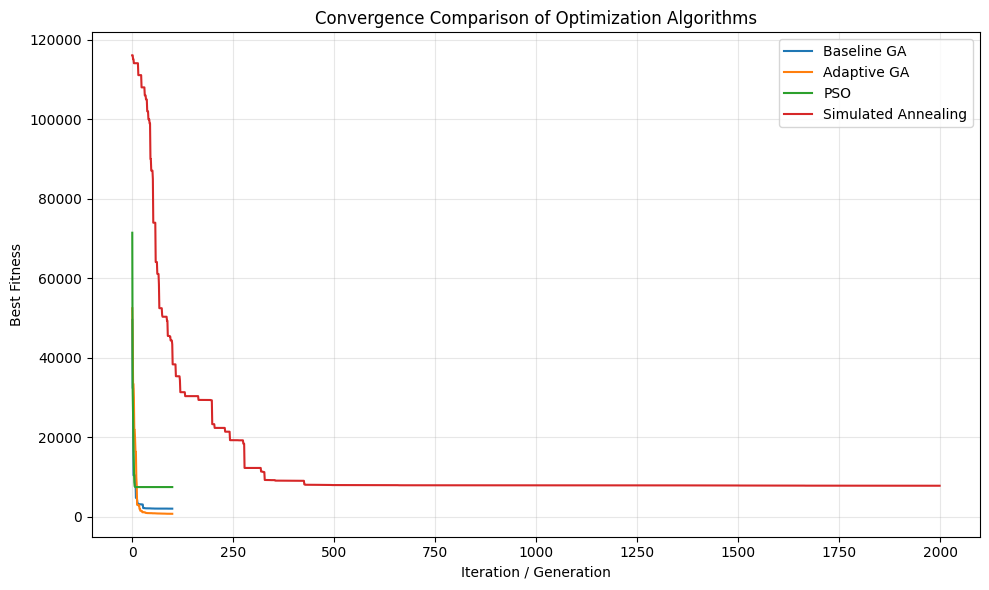

In [60]:
plt.figure(figsize=(10, 6))

plt.plot(baseline_dynamic_history, label="Baseline GA")
plt.plot(adaptive_dynamic_history, label="Adaptive GA")
plt.plot(pso_history, label="PSO")
plt.plot(sa_history, label="Simulated Annealing")

plt.title("Convergence Comparison of Optimization Algorithms")
plt.xlabel("Iteration / Generation")
plt.ylabel("Best Fitness")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [64]:
algorithm_results = {
    "Baseline GA": 476.63,
    "Adaptive GA": 438.31,
    "PSO": 7457.32,
    "Simulated Annealing": 7791.41
}

best_algorithm = min(
    algorithm_results,
    key=algorithm_results.get
)

print("Selected Algorithm:", best_algorithm)
print("Best Fitness:", algorithm_results[best_algorithm])

Selected Algorithm: Adaptive GA
Best Fitness: 438.31


In [66]:

# ============================================
# NEXT CELL: WINNER ANALYSIS
# ============================================

baseline_fitness = algorithm_results["Baseline GA"]
adaptive_fitness = algorithm_results["Adaptive GA"]

improvement = (
    (baseline_fitness - adaptive_fitness)
    / baseline_fitness
) * 100

print("FINAL ALGORITHM SELECTION")
print("--------------------------------")

print("Selected Algorithm:", best_algorithm)
print("Best Fitness:", round(algorithm_results[best_algorithm], 2))

print("\nREASON FOR SELECTION")
print("--------------------------------")

print(
    f"Adaptive GA achieved {improvement:.2f}% "
    "lower fitness than Baseline GA."
)

print(
    "It obtained the lowest fitness among all four "
    "algorithms in this experiment."
)


FINAL ALGORITHM SELECTION
--------------------------------
Selected Algorithm: Adaptive GA
Best Fitness: 438.31

REASON FOR SELECTION
--------------------------------
Adaptive GA achieved 8.04% lower fitness than Baseline GA.
It obtained the lowest fitness among all four algorithms in this experiment.
